# Contour plot testing

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.colors as colors
from matplotlib import ticker
from math import pi
from decimal import Decimal
from plotting_functions import *

In [2]:
# Set parameters for all plots in notebook
file = "../Outputs/1e7_test.csv"
z_slice = 25
norm_point = (0.3, 0.0)
bins = 51
dose_grid_half = 1.25
lattice = dose_grid_half*2/bins
source_transZ = -0.5
source_plane = cm_to_voxel(np.array(source_transZ), bins, dose_grid_half*2/bins)

source_rad = 0.3
rngX = (-1.0, 1.0)
rngY = (-1.0, 1.0)

## Scaling energy before processing

### 0.0 Scale = False w/out zeroing the source

In [3]:
X0, Y0, energy0, std_dev0 = contour_energy(file, (bins, bins), dose_grid_half, source_plane, 2, rngX, rngY, 
                                           source_rad=source_rad, scale=False, norm_point=norm_point, zero_source=False, std_dev=False)

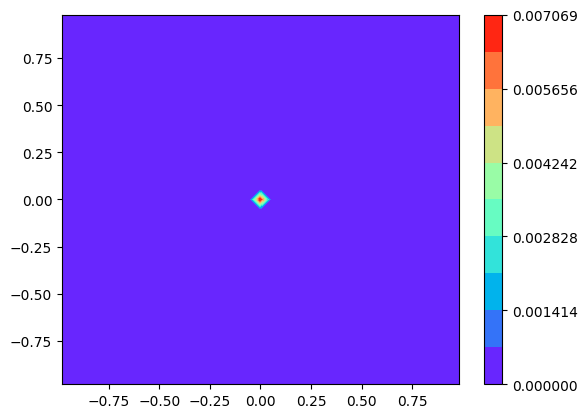

In [4]:
# Linear norm
fig0a, ax0a = plt.subplots()
contour = ax0a.contourf(X0, Y0, energy0, locator=ticker.LinearLocator(), norm="linear", cmap="rainbow")
cbar = fig0a.colorbar(contour)

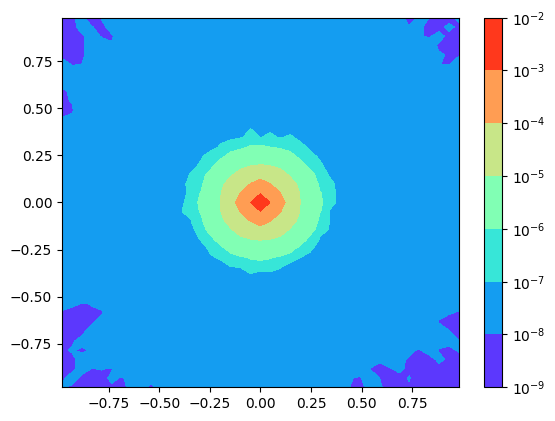

In [5]:
# Log norm
fig0b, ax0b = plt.subplots()
contour = ax0b.contourf(X0, Y0, energy0, locator=ticker.LogLocator(), norm="log", cmap="rainbow")
cbar = fig0b.colorbar(contour)

### 0.1 Scale = False w/zeroing source

In [6]:
X01, Y01, energy01, std_dev01 = contour_energy(file, (bins, bins), dose_grid_half, source_plane, 2, rngX, rngY, 
                                           source_rad=source_rad, scale=False, norm_point=norm_point, zero_source=True, std_dev=False)

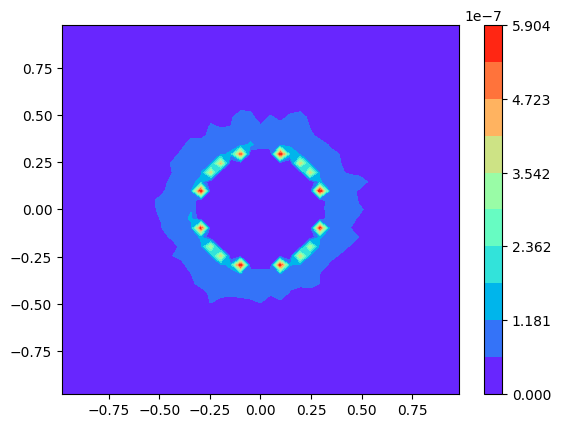

In [7]:
# Linear norm
fig01a, ax01a = plt.subplots()
contour = ax01a.contourf(X01, Y01, energy01, locator=ticker.LinearLocator(), norm="linear", cmap="rainbow")
cbar = fig01a.colorbar(contour)

/var/folders/8h/nlsnrxxs1mg885p2fr80gs240000gn/T/ipykernel_43226/4020078797.py:3: UserWarning: Log scale: values of z <= 0 have been masked
  contour = ax01b.contourf(X01, Y01, energy01, locator=ticker.LogLocator(), norm="log", cmap="rainbow")


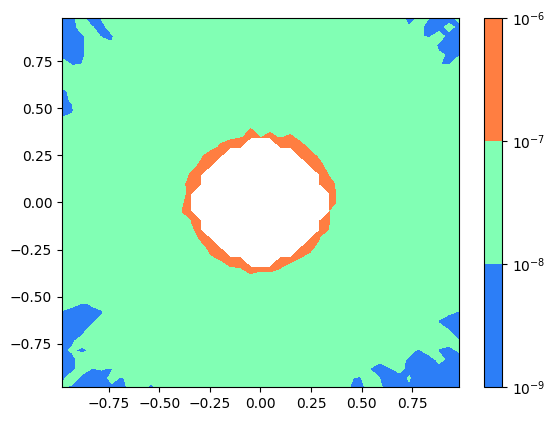

In [8]:
# Log norm
fig01b, ax01b = plt.subplots()
contour = ax01b.contourf(X01, Y01, energy01, locator=ticker.LogLocator(), norm="log", cmap="rainbow")
cbar = fig01b.colorbar(contour)

### 1.0 Scale = True w/out zeroing the source

In [9]:
X1, Y1, energy1, std_dev1 = contour_energy(file, (bins, bins), dose_grid_half, source_plane, 2, rngX, rngY, 
                                       source_rad=source_rad, scale=True, norm_point=norm_point, zero_source=False, std_dev=False)

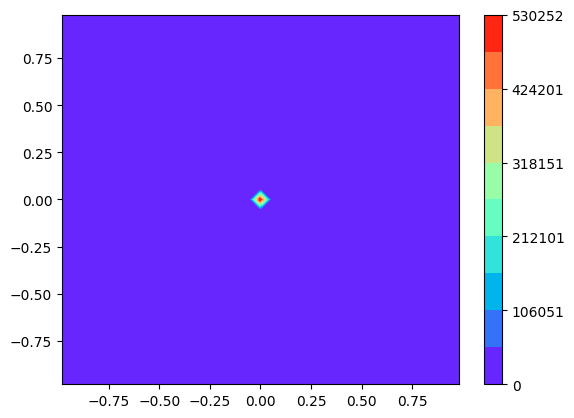

In [10]:
# Linear norm
fig1a, ax1a = plt.subplots()
contour = ax1a.contourf(X1, Y1, energy1, locator=ticker.LinearLocator(), norm="linear", cmap="rainbow")
cbar = fig1a.colorbar(contour)

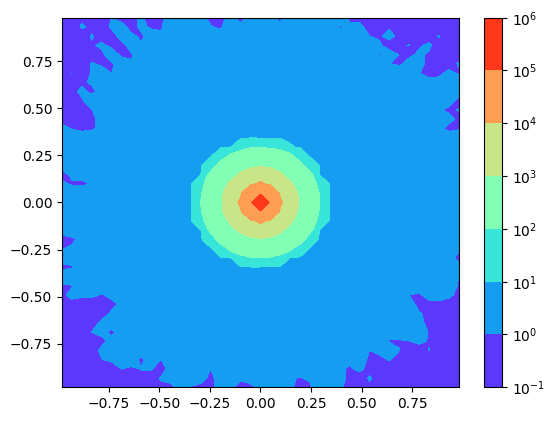

In [11]:
# Log norm
fig1b, ax1b = plt.subplots()
contour = ax1b.contourf(X1, Y1, energy1, locator=ticker.LogLocator(), norm="log", cmap="rainbow")
cbar = fig1b.colorbar(contour)

### 1.1 Scale = True w/zeroing source

In [12]:
X11, Y11, energy11, std_dev11 = contour_energy(file, (bins, bins), dose_grid_half, source_plane, 2, rngX, rngY, 
                                           source_rad=source_rad, scale=True, norm_point=norm_point, zero_source=True, std_dev=False)

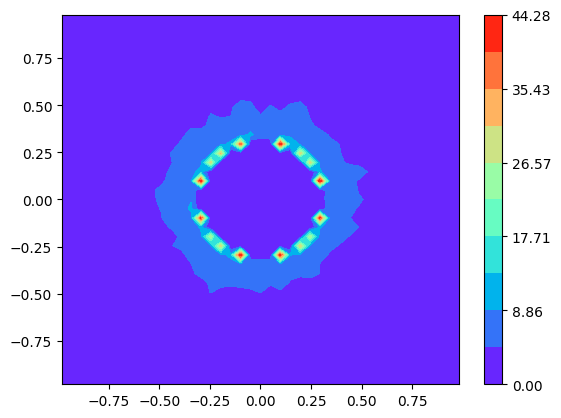

In [13]:
# Linear norm
fig11a, ax11a = plt.subplots()
contour = ax11a.contourf(X11, Y11, energy11, locator=ticker.LinearLocator(), norm="linear", cmap="rainbow")
cbar = fig11a.colorbar(contour)

/var/folders/8h/nlsnrxxs1mg885p2fr80gs240000gn/T/ipykernel_43226/2550998334.py:3: UserWarning: Log scale: values of z <= 0 have been masked
  contour = ax11b.contourf(X11, Y11, energy11, locator=ticker.LogLocator(), norm="log", cmap="rainbow")


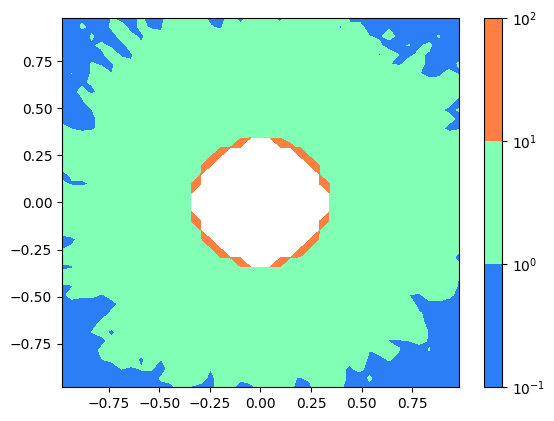

In [14]:
# Log norm
fig11b, ax11b = plt.subplots()
contour = ax11b.contourf(X11, Y11, energy11, locator=ticker.LogLocator(), norm="log", cmap="rainbow")
cbar = fig11b.colorbar(contour)

## Scaling energy after processing

In [15]:
# Define manual normalization
volume = np.genfromtxt(file, delimiter=",")
plane = volume[volume[:,2] == source_plane]
plane = np.delete(plane, 2, 1)
norm_energy, __ = norm_energy_debug(plane, norm_point, bins, lattice)

vmax = 200

def _forward(x, norm_energy=norm_energy):
	return (x/norm_energy)*100

def _inverse(y, norm_energy=norm_energy):
	return (y/100)*norm_energy

norm = colors.FuncNorm((_forward, _inverse), vmin=0, vmax=vmax, clip=True)

### 2.0 Scale = False w/out zeroing source

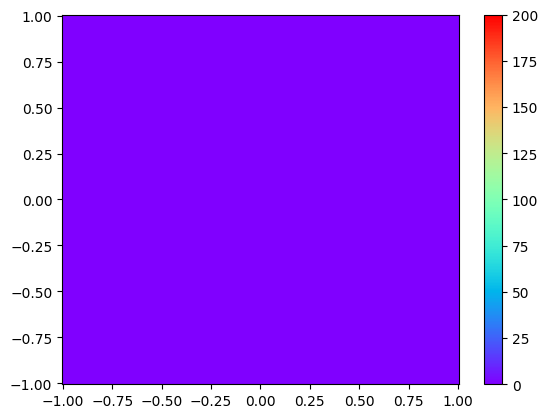

In [16]:
X2, Y2, energy2, std_dev2 = contour_energy(file, (bins, bins), dose_grid_half, source_plane, 2, rngX, rngY, 
                                           source_rad=source_rad, scale=False, norm_point=norm_point, zero_source=False, std_dev=False)
fig20, ax20 = plt.subplots()
test = ax20.pcolormesh(X2, Y2, energy2, norm=norm, cmap="rainbow")
cbar = fig20.colorbar(test)

### 2.1 Scale = False w/zeroing source

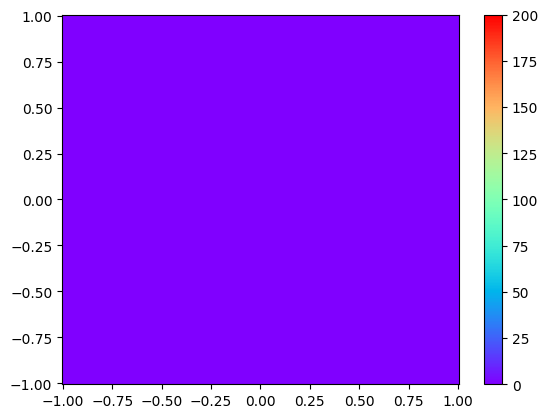

In [17]:
X21, Y21, energy21, std_dev21 = contour_energy(file, (bins, bins), dose_grid_half, source_plane, 2, rngX, rngY, 
                                           source_rad=source_rad, scale=False, norm_point=norm_point, zero_source=True, std_dev=False)
fig21, ax21 = plt.subplots()
test = ax21.pcolormesh(X21, Y21, energy21, norm=norm, cmap="rainbow")
cbar = fig21.colorbar(test)

### 2.2 Scale = True w/out zeroing source

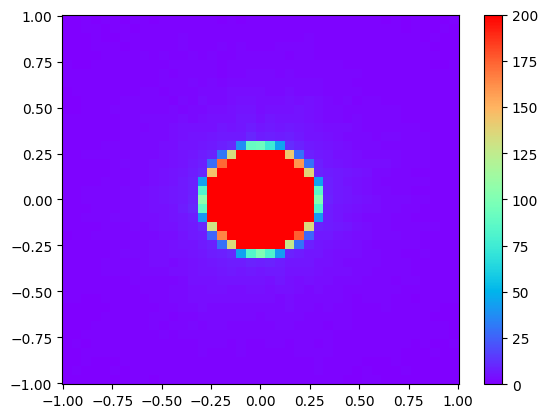

In [18]:
X22, Y22, energy22, std_dev22 = contour_energy(file, (bins, bins), dose_grid_half, source_plane, 2, rngX, rngY, 
                                           source_rad=source_rad, scale=True, norm_point=norm_point, zero_source=False, std_dev=False)
fig22, ax22 = plt.subplots()
test = ax22.pcolormesh(X22, Y22, energy22, norm=norm, cmap="rainbow")
cbar = fig22.colorbar(test)

### 2.3 Scale = True w/zeroing source

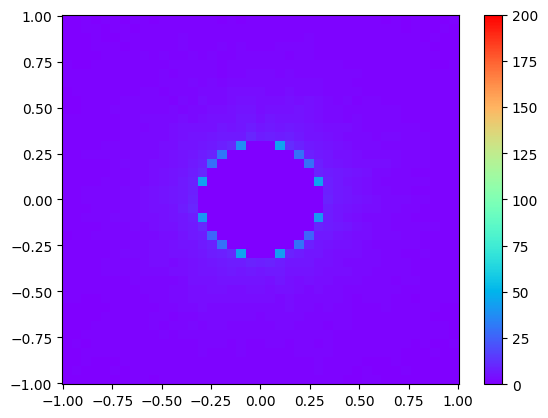

In [19]:
X23, Y23, energy23, std_dev23 = contour_energy(file, (bins, bins), dose_grid_half, source_plane, 2, rngX, rngY, 
                                           source_rad=source_rad, scale=True, norm_point=norm_point, zero_source=True, std_dev=False)
fig23, ax23 = plt.subplots()
test = ax23.pcolormesh(X23, Y23, energy23, norm=norm, cmap="rainbow")
cbar = fig23.colorbar(test)